# 0. Engine Fit Diagnostics
- Figures backing the model-structure Methods: PCIS cut, dispersion EB shrinkage, masking demonstration.
- Reads saved engine outputs only (`config.ENGINE_DIR`, `config.PCIS_CAL_DIR`); no refit.
- Figures -> `config.ENGINE_DIAG_DIR / 'Figures'`

In [9]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.environ["NM_PIPELINE"] = "p0"
sys.path.insert(0, str(Path.cwd().parents[1]))
import MixedEffectsModeling.config as config
from viz_style import apply_style
apply_style()

FIG = config.ENGINE_DIAG_DIR / "Figures"
FIG.mkdir(parents=True, exist_ok=True)
CUT = config.FIT_PARAMS["pcis_cut"]
train = pd.read_csv(config.ENGINE_DIR / "training_summary.csv")
model_ok = train[(train.route == "model") & train.ok.astype(bool)]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. PCIS null calibration and observed removals
- A: per-observation false-removal rate of the parametric-bootstrap null as a function of the PCIS threshold; the deployed cut is the 1e-4 quantile.
- B: observations removed per gene in the deployed fit (individually fitted genes only; pooled low-nz genes have no PCIS step).

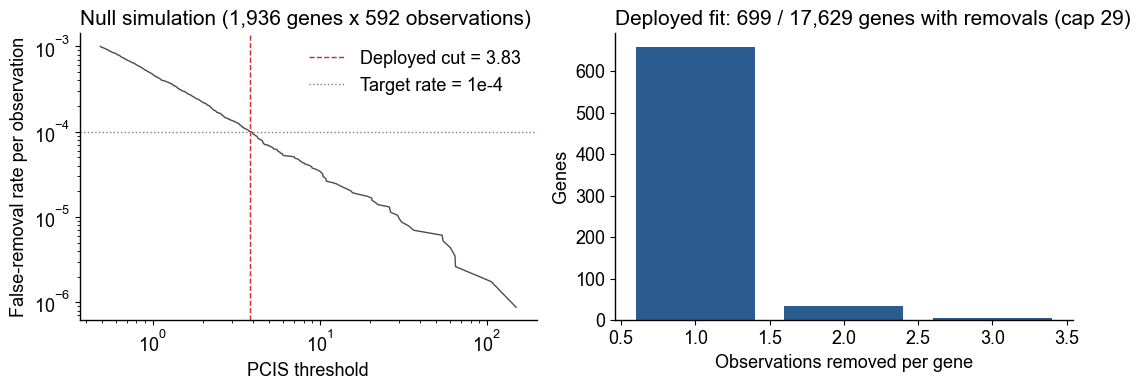

null: 1936 genes, 1936 gene-replicates, 1,146,112 observations
 target_per_obs_rate       cut  null_removed_per_gene
             0.00100  0.486199               0.591426
             0.00050  0.948875               0.295455
             0.00030  1.505539               0.177169
             0.00020  2.182911               0.117769
             0.00015  2.670702               0.088326
             0.00010  3.825780               0.058884
             0.00005  7.079971               0.028926
             0.00001 29.887675               0.005165
observed removals per gene (individually fitted): mean 0.042, max 3


In [10]:
null = pd.read_csv(config.PCIS_CAL_DIR / "null_pcis_top50_raw.csv.gz")
null = null[np.isfinite(null.pcis)]
n_obs = int(null.n_obs.iloc[0])
n_units = null.groupby(["gene", "rep"]).ngroups
pcis = np.sort(null.pcis.values)[::-1]
rate = np.arange(1, len(pcis) + 1) / (n_units * n_obs)
keep = rate <= 1e-3
rt = pd.read_csv(config.PCIS_CAL_DIR / "pcis_rate_table.csv")
assert abs(rt.loc[rt.target_per_obs_rate == 1e-4, "cut"].item() - CUT) < 0.01
cap = int(np.floor(config.FIT_PARAMS["max_outlier_frac"] * n_obs))
n_out = model_ok.n_outliers.astype(int)
vc = n_out[n_out > 0].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.loglog(pcis[keep], rate[keep], color="0.3")
ax.axvline(CUT, color="#d62828", ls="--", label=f"Deployed cut = {CUT:.2f}")
ax.axhline(1e-4, color="0.5", ls=":", label="Target rate = 1e-4")
ax.set_xlabel("PCIS threshold")
ax.set_ylabel("False-removal rate per observation")
ax.set_title(f"Null simulation ({null.gene.nunique():,} genes x {n_obs} observations)", loc="left")
ax.legend(frameon=False)
ax = axes[1]
ax.bar(vc.index, vc.values, color="#2b5c8f")
ax.set_xlabel("Observations removed per gene")
ax.set_ylabel("Genes")
ax.set_title(f"Deployed fit: {int((n_out > 0).sum()):,} / {len(model_ok):,} genes with removals (cap {cap})", loc="left")
plt.tight_layout()
plt.savefig(FIG / "fig1_pcis_null_cut.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"null: {null.gene.nunique()} genes, {n_units} gene-replicates, {n_units * n_obs:,} observations")
print(rt[["target_per_obs_rate", "cut", "null_removed_per_gene"]].to_string(index=False))
print(f"observed removals per gene (individually fitted): mean {n_out.mean():.3f}, max {n_out.max()}")

## 2. Low-nz convergence and the pooling threshold
- Every gene with nz in [1, 60] refitted through the individual cascade on all HC and on the 5 CV training folds.
- Producer: `NM_PIPELINE=p0 python MixedEffectsModeling/notebookscripts/EngineDiagnostics/low_nz_convergence.py` -> `config.ENGINE_DIAG_DIR / 'low_nz_convergence.csv'`
- Genes left of the line are routed to the pooled GLM in the deployed engine.

In [11]:
conv = pd.read_csv(config.ENGINE_DIAG_DIR / "low_nz_convergence.csv", index_col="gene")
edges = np.arange(0, 61, 5)
conv["nz_bin"] = pd.cut(conv.nz, edges)
by = conv.groupby("nz_bin", observed=True).agg(
    n=("nz", "size"), full_ok=("full_ok", "mean"), all5=("n_fold_ok", lambda s: (s == 5).mean()))
x = (edges[:-1] + edges[1:]) / 2
x = x[: len(by)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, by.full_ok, marker="o", color="#2b5c8f", label="Converged on all HC")
ax.plot(x, by.all5, marker="s", color="#d62828", label="Converged in all 5 CV folds")
ax.axvline(config.NZ_A_MAX - 0.5, color="0.3", ls="--", label=f"Pooling threshold (nz < {config.NZ_A_MAX})")
for xi, n in zip(x, by.n):
    ax.text(xi, 0.02, f"{n}", ha="center", fontsize=8, color="0.4")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Non-zero HC samples per gene (nz)")
ax.set_ylabel("Fraction of genes")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "fig2_low_nz_convergence.png", dpi=300, bbox_inches="tight")
plt.show()
print(by.round(3).to_string())
print(conv.loc[~conv.full_ok, "nbi_intercept_eb_reject_reason"].fillna("(blank)").value_counts().to_string())

FileNotFoundError: [Errno 2] No such file or directory: '/project/cfRNA_NormativeModeling/MixedEffectsModeling/Notebook_p0/8_EngineDiagnostics/low_nz_convergence.csv'

## 3. PCIS on the deployed fit: masking under the gene's own dispersion
- Producer: `NM_PIPELINE=p0 python MixedEffectsModeling/notebookscripts/EngineDiagnostics/pcis_case_study.py` (case study + section 4 simulation).
- Every deployed gene with PCIS removals is refitted with all observations; the removed observations are scored three ways on that same fit:
  - PCIS (trend dispersion, mixed leverage) = deployed score
  - PCIS with the gene's own fitted dispersion = what the score would be without the trend
  - classical Cook's distance (own dispersion, fixed-effect leverage, thresholds 1 and 4/n)
- `alpha_own_with / alpha_own_without`: how much the removed observations inflated the gene's own dispersion.

In [ ]:
gcase = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_cases_gene.csv")
obs = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_cases_obs.csv.gz")
n_hc = len(pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_cases_samples.csv"))
gcase["inflation"] = gcase.alpha_own_with / gcase.alpha_own_without
rem = obs[obs.removed].merge(gcase[["gene", "n_drop"]], on="gene")
print(f"removal count reproduced: {(gcase.n_drop == gcase.n_outliers_deployed).mean():.3f} ({len(gcase)} genes)")

flag = rem.assign(pcis_trend=rem.pcis_trend > CUT, pcis_own=rem.pcis_own > CUT,
                  cooks_1=rem.cooks > 1, cooks_4n=rem.cooks > 4 / n_hc)
display(flag.groupby("n_drop")[["pcis_trend", "pcis_own", "cooks_1", "cooks_4n"]].mean()
        .assign(n_obs=flag.groupby("n_drop").size()).round(3))
display(gcase.groupby("n_drop").inflation.describe(percentiles=[0.5]).round(2))

grp = np.where(rem.n_drop >= 2, ">=2 removed in gene", "1 removed in gene")
col = {"1 removed in gene": "0.6", ">=2 removed in gene": "#d62828"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, ycol, ycuts, ylab in [(axes[0], "pcis_own", [CUT], "PCIS with own dispersion"),
                              (axes[1], "cooks", [1, 4 / n_hc], "Classical Cook's distance")]:
    for k, c in col.items():
        m = grp == k
        ax.scatter(rem.pcis_trend[m], rem[ycol][m], s=10, color=c, alpha=0.7, label=k)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axvline(CUT, color="0.3", ls="--")
    for yc in ycuts:
        ax.axhline(yc, color="0.3", ls=":")
    ax.set_xlabel("PCIS (trend dispersion, deployed)")
    ax.set_ylabel(ylab)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_title("Removed observations: deployed vs own-dispersion score", loc="left")
axes[1].set_title("Removed observations: deployed vs Cook's distance", loc="left")
ax = axes[2]
for i, k in enumerate(sorted(gcase.n_drop.unique())):
    v = np.log2(gcase.loc[gcase.n_drop == k, "inflation"].dropna())
    ax.boxplot(v, positions=[i], widths=0.6, showfliers=False)
    ax.scatter(np.random.default_rng(0).normal(i, 0.06, len(v)), v, s=6, color="0.4", alpha=0.5)
ax.set_xticks(range(gcase.n_drop.nunique()))
ax.set_xticklabels(sorted(gcase.n_drop.unique()))
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("Observations removed per gene")
ax.set_ylabel("log2 own dispersion: with / without removed obs")
ax.set_title("Own-dispersion inflation by the removed observations", loc="left")
plt.tight_layout()
plt.savefig(FIG / "fig3_pcis_masking_real.png", dpi=300, bbox_inches="tight")
plt.show()

### 3b. Example genes with 2-3 removed observations
- Observed count vs fitted mean (all observations kept); removed observations in red.

In [ ]:
multi = gcase[gcase.n_drop >= 2].sort_values(["n_drop", "inflation"], ascending=False).head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (_, g) in zip(axes.ravel(), multi.iterrows()):
    o = obs[obs.gene == g.gene]
    ax.scatter(np.log1p(o.mu), np.log1p(o.y), s=8, color="0.6")
    r = o[o.removed]
    ax.scatter(np.log1p(r.mu), np.log1p(r.y), s=40, color="#d62828", edgecolor="black", zorder=3)
    lim = [0, max(np.log1p(o.y).max(), np.log1p(o.mu).max()) * 1.05]
    ax.plot(lim, lim, color="0.3", lw=0.8)
    ax.set_title(f"{g.symbol}: own alpha {g.alpha_own_with:.3g} -> {g.alpha_own_without:.3g} "
                 f"(trend {g.trend_alpha:.3g})", loc="left", fontsize=9)
    ax.set_xlabel("log1p fitted mean")
    ax.set_ylabel("log1p observed count")
    txt = "\n".join(f"PCIS {a:.1f} | own {b:.2f} | Cook {c:.3f}" for a, b, c in zip(r.pcis_trend, r.pcis_own, r.cooks))
    ax.text(0.02, 0.98, txt, transform=ax.transAxes, va="top", fontsize=7)
plt.tight_layout()
plt.savefig(FIG / "fig3b_pcis_example_genes.png", dpi=300, bbox_inches="tight")
plt.show()
display(multi[["symbol", "n_drop", "trend_alpha", "alpha_own_with", "alpha_own_without", "inflation",
               "tau2_with", "tau2_without", "max_abs_dbeta", "refit_ok"]].round(3))

## 4. Masking simulation on selected genes
- 4 calibration genes at the 20/50/80/95th percentile of HC mean count; clean counts regenerated from their fitted mean, dispersion and batch variance on the real design.
- 2 or 3 outliers at 5/10/20x the mean, placed at random or inside one batch; 30 replicates per condition; k = 0 is the clean null.
- Detection = fraction of injected observations above each score's threshold; FP = clean observations above it per fit.

In [ ]:
sim = pd.read_csv(config.ENGINE_DIAG_DIR / "pcis_masking_sim.csv")
METH = {"pcis_trend": ("PCIS (trend dispersion)", "#2b5c8f"), "pcis_own": ("PCIS (own dispersion)", "#e07a5f"),
        "cooks_1": ("Cook's D > 1", "0.3"), "cooks_4n": ("Cook's D > 4/n", "0.65")}
null = sim[sim.k == 0]
print("clean null, false flags per observation:")
print((null[[f"fp_{m}" for m in METH]].sum() / (len(null) * n_hc)).round(6).to_string())

inj = sim[sim.k > 0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, place in zip(axes[:2], ["random", "same_batch"]):
    d = inj[inj.place == place].groupby(["k", "m"])[[f"tpr_{m}" for m in METH]].mean().reset_index()
    for m, (lab, c) in METH.items():
        for k, ls in [(2, "-"), (3, "--")]:
            s = d[d.k == k]
            ax.plot(s.m, s[f"tpr_{m}"], ls=ls, marker="o", color=c, label=f"{lab}, k={k}")
    ax.set_xscale("log"); ax.set_xticks([5, 10, 20]); ax.set_xticklabels([5, 10, 20])
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("Outlier magnitude (x mean)")
    ax.set_ylabel("Fraction of injected outliers detected")
    ax.set_title(f"Outliers placed: {place.replace('_', ' ')}", loc="left")
axes[0].legend(frameon=False, fontsize=7)
ax = axes[2]
d = inj.groupby(["k", "m"]).apply(lambda s: pd.Series({
    "with": np.median(s.alpha_own / s.alpha_true),
    "after": np.median(s.alpha_after_removal / s.alpha_true)})).reset_index()
for k, ls in [(2, "-"), (3, "--")]:
    s = d[d.k == k]
    ax.plot(s.m, s["with"], ls=ls, marker="o", color="#e07a5f", label=f"own dispersion with outliers, k={k}")
    ax.plot(s.m, s["after"], ls=ls, marker="s", color="#2b5c8f", label=f"after PCIS removal + refit, k={k}")
ax.axhline(1, color="0.3", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks([5, 10, 20]); ax.set_xticklabels([5, 10, 20])
ax.set_xlabel("Outlier magnitude (x mean)")
ax.set_ylabel("Fitted / true dispersion (median)")
ax.set_title("Dispersion inflation and recovery", loc="left")
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig(FIG / "fig4_pcis_masking_sim.png", dpi=300, bbox_inches="tight")
plt.show()
display(inj.groupby(["mean_hc", "k", "m", "place"])[[f"tpr_{m}" for m in METH]].mean().round(2))

## 5. Dispersion trend (E1)
- Calibration fits (no prior, stratified 2,000 genes, 1,936 converged): dispersion at the covariate mean vs HC mean count, with the deployed lowess trend.
- B: per-expression-bin median and IQR of log(alpha_fit / alpha_trend); a trend without expression-dependent bias stays near 0 in every bin.

In [ ]:
import json
import pickle
from MixedEffectsModeling.core.dispersion_trend import load_trend

CAL_MEAN = config.ENGINE_DIAG_DIR / "calib_gene_mean.csv"
calib = pd.read_csv(config.ENGINE_DIR / "calib_fits.csv")
if CAL_MEAN.is_file():
    cmean = pd.read_csv(CAL_MEAN, index_col="gene")["mean_hc"]
else:
    import scanpy as sc
    hc = pd.read_csv(config.ZSCORES_DIR / "hc_meta.csv")["sample"].values
    ad = sc.read_h5ad(config.H5AD_PATH, backed="r")
    assert np.isin(hc, ad.obs_names).all()
    Xc = ad[hc, calib.gene.values].to_memory().X
    Xc = Xc.toarray() if hasattr(Xc, "toarray") else np.asarray(Xc)
    cmean = pd.Series(np.round(Xc).mean(0), index=pd.Index(calib.gene.values, name="gene"), name="mean_hc")
    cmean.to_frame().to_csv(CAL_MEAN)

alpha_of = load_trend(config.ENGINE_DIR / "dispersion_trend.json")
cal = calib[calib.ok.astype(bool)].copy()
cal["mean_hc"] = cmean.reindex(cal.gene).values
cal["alpha_fit"] = np.exp(-cal.disp_coef_0)
cal["alpha_trend"] = [alpha_of(m) for m in cal.mean_hc]
cal["resid"] = np.log(cal.alpha_fit) - np.log(cal.alpha_trend)
cal["bin"] = pd.qcut(np.log(cal.mean_hc), 12)
tb = cal.groupby("bin", observed=True).agg(mu=("mean_hc", "median"), med=("resid", "median"),
                                           q25=("resid", lambda s: s.quantile(0.25)),
                                           q75=("resid", lambda s: s.quantile(0.75)), n=("resid", "size"))
grid = np.geomspace(cal.mean_hc.min(), cal.mean_hc.max(), 200)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.scatter(cal.mean_hc, cal.alpha_fit, s=3, alpha=0.25, color="0.5", rasterized=True, label=f"Calibration fits (n={len(cal):,})")
ax.plot(grid, [alpha_of(m) for m in grid], color="#2b5c8f", lw=2.2, label="Lowess trend (frac 0.3, 3 iterations)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("HC mean count"); ax.set_ylabel("NB dispersion alpha")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.axhline(0, color="0.3", lw=0.8)
ax.fill_between(tb.mu, tb.q25, tb.q75, color="#2b5c8f", alpha=0.2, lw=0, label="IQR")
ax.plot(tb.mu, tb.med, "s-", color="#2b5c8f", label="Bin median")
ax.set_xscale("log")
ax.set_xlabel("HC mean count"); ax.set_ylabel("log(alpha_fit / alpha_trend)")
ax.set_title(f"max |bin median| = {tb.med.abs().max():.3f}", loc="left")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "fig5_dispersion_trend.png", dpi=300, bbox_inches="tight")
plt.show()
mad_sd = 1.4826 * np.median(np.abs(cal.resid - cal.resid.median()))
print(f"genes {len(cal)} | residual median {cal.resid.median():+.3f} | robust sd {mad_sd:.3f} | max |bin median| {tb.med.abs().max():.3f}")

## 6. Dispersion slope prior (E2)
- A: per covariate, calibration slope estimates without prior; markers = +-omega_k (deployed prior sd).
- B/C: the same genes' slopes in the deployed fit (with prior) vs the calibration fit (no prior).
  - The deployed fit also ran PCIS removal, which the calibration fit did not; the comparison mixes both effects for the few genes with removals.
- A prior that only stabilizes keeps the ordering of slopes (high correlation) and shrinks their spread modestly.

In [ ]:
genes = pickle.load(open(config.ENGINE_DIR / "genes.pkl", "rb"))
prior = json.load(open(config.ENGINE_DIR / "disp_prior.json"))
covs, omega = prior["covariates"], np.asarray(prior["tau_slope"])
cal_full = cal[cal.stage == "nbi_full_eb"].set_index("gene")
common = [g for g in cal_full.index if g in genes and genes[g].ok and genes[g].stage == "nbi_full_eb"]
raw = cal_full.loc[common, [f"disp_coef_{k}" for k in range(1, len(covs) + 1)]].to_numpy(float)
post = np.array([genes[g].disp_coef[1:len(covs) + 1] for g in common], dtype=float)

stats = pd.DataFrame({
    "omega_k": omega,
    "raw_robust_sd": [1.4826 * np.nanmedian(np.abs(r - np.nanmedian(r))) for r in raw.T],
    "median_se": [np.nanmedian(cal_full.loc[common, f"disp_se_{k}"]) for k in range(1, len(covs) + 1)],
    "sd_ratio_post_raw": np.nanstd(post, 0) / np.nanstd(raw, 0),
    "spearman_post_raw": [pd.Series(raw[:, k]).corr(pd.Series(post[:, k]), method="spearman") for k in range(len(covs))],
}, index=covs)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
ax = axes[0]
y = np.arange(len(covs))
ax.violinplot([r[np.isfinite(r)] for r in raw.T], positions=y, vert=False, showextrema=False, widths=0.8)
ax.scatter(-omega, y, marker="|", s=200, color="#d62828")
ax.scatter(omega, y, marker="|", s=200, color="#d62828", label="+- omega_k (prior sd)")
ax.set_yticks(y); ax.set_yticklabels(covs, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("Dispersion slope, calibration fit (no prior)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax = axes[1]
ax.scatter(raw.ravel(), post.ravel(), s=2, alpha=0.15, color="0.4", rasterized=True)
lim = np.nanpercentile(np.abs(raw), 99.5)
ax.plot([-lim, lim], [-lim, lim], color="#d62828", lw=0.8)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("Slope without prior (calibration)"); ax.set_ylabel("Slope with prior (deployed)")
ax.set_title(f"{len(common):,} genes x {len(covs)} covariates", loc="left")
ax = axes[2]
ax.barh(y, stats.sd_ratio_post_raw, color="#2b5c8f", label="SD ratio (with / without prior)")
ax.scatter(stats.spearman_post_raw, y, color="#d62828", zorder=3, label="Spearman (with vs without)")
ax.axvline(1, color="0.3", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(covs, fontsize=8); ax.invert_yaxis()
ax.set_xlim(0, 1.1)
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(FIG / "fig6_dispersion_slope_prior.png", dpi=300, bbox_inches="tight")
plt.show()
display(stats.round(3))

## 7. Dispersion intercept squeeze (E3)
- log theta intercept before (raw MLE) and after the EB squeeze toward the trend, deployed engine, individually fitted genes.
- Shrink fraction = (eb - raw) / (trend - raw): 0 keeps the gene's own estimate, 1 pins it to the trend.
- Under the precision-weighted rule the expected fraction is SE^2 / (SE^2 + omega_d^2); genes with no usable SE take the trend (fraction 1).

In [ ]:
omega_d = json.load(open(config.ENGINE_DIR / "eb_meta.json"))["disp_tau_d"]
rec = pd.DataFrame([dict(gene=g, nz=r.nz, stage=r.stage, raw=r.log_theta_raw, eb=r.log_theta_eb,
                         trend=-np.log(r.trend_alpha), se=r.disp_se[0])
                    for g, r in genes.items() if r.ok and r.route == "model" and r.log_theta_eb is not None])
gap = rec.trend - rec.raw
rec["frac"] = np.where(np.abs(gap) > 1e-6, (rec.eb - rec.raw) / gap.where(np.abs(gap) > 1e-6, 1), np.nan)
rec["frac_expected"] = rec.se ** 2 / (rec.se ** 2 + omega_d ** 2)
print(f"genes {len(rec):,} | omega_d {omega_d:.3f} | no usable SE (pinned to trend): {int(rec.se.isna().sum())} "
      f"| |observed - expected fraction| max {np.nanmax(np.abs(rec.frac - rec.frac_expected)):.2e}")
rec["nz_bin"] = pd.cut(rec.nz, [30, 60, 100, 200, 300, 400, 500, 550, 592])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ax = axes[0]
sc_ = ax.scatter(rec.raw, rec.eb, c=np.log10(rec.se), s=3, cmap="viridis", alpha=0.6, rasterized=True)
lim = [np.nanmin(rec.raw), np.nanmax(rec.raw)]
ax.plot(lim, lim, color="#d62828", lw=0.8)
ax.set_xlabel("log theta intercept, raw MLE"); ax.set_ylabel("log theta intercept, after squeeze")
plt.colorbar(sc_, ax=ax, label="log10 SE")
ax = axes[1]
ax.scatter(rec.se, rec.frac, s=3, alpha=0.3, color="0.4", rasterized=True)
sg = np.geomspace(np.nanmin(rec.se), np.nanmax(rec.se), 200)
ax.plot(sg, sg ** 2 / (sg ** 2 + omega_d ** 2), color="#d62828", label=f"SE^2 / (SE^2 + omega_d^2), omega_d = {omega_d:.3f}")
ax.set_xscale("log"); ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("SE of raw intercept"); ax.set_ylabel("Shrink fraction toward trend")
ax.legend(frameon=False, fontsize=8)
ax = axes[2]
b = rec.groupby("nz_bin", observed=True).frac
x = np.arange(b.ngroups)
ax.plot(x, b.median(), "o-", color="#2b5c8f", label="Median")
ax.fill_between(x, b.quantile(0.25), b.quantile(0.75), color="#2b5c8f", alpha=0.2, lw=0, label="IQR")
ax.set_xticks(x); ax.set_xticklabels([str(i) for i in b.median().index], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("Non-zero HC samples per gene (nz)"); ax.set_ylabel("Shrink fraction toward trend")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "fig7_dispersion_intercept_squeeze.png", dpi=300, bbox_inches="tight")
plt.show()
display(rec.groupby("nz_bin", observed=True).agg(n=("frac", "size"), frac_median=("frac", "median"),
                                                  se_median=("se", "median")).round(3))